# Installs

In [6]:
%pip install xgboost -v
%pip install matplotlib seaborn
%pip install scikit-learn
%pip install pandas
%pip install numpy
%pip install --upgrade scipy
%pip install optuna

/Users/andrewmattei/Machine-Learning-Project/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.
/Users/andrewmattei/Machine-Learning-Project/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.
/Users/andrewmattei/Machine-Learning-Project/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.
/Users/andrewmattei/Machine-Learning-Project/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.
/Users/andrewmattei/Machine-Learning-Project/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.
/Users/andrewmattei/Machine-Learning-Project/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.
/Users/andrewmattei/Machine-Learning-Project/.venv/bin/python: No module named pip
Note: you may need to r

# Imports

In [7]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier, plot_importance
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

# Load the Data from CSV Files

In [8]:
# Define the paths to your processed data
# Adjust the path if your notebook is inside a 'notebooks' folder
TRAIN_PATH = '../data/processed/fights_training.csv'
VAL_PATH = '../data/processed/fights_validation.csv'
TEST_PATH = '../data/processed/fights_testing.csv'

# 1. Reload the data to ensure a completely clean slate
train = pd.read_csv(TRAIN_PATH)
val = pd.read_csv(VAL_PATH)
test = pd.read_csv(TEST_PATH)

# 2. Define exactly what we want to drop
columns_to_drop = ['winner']

# 3. Split into Features (X) and Target (y)
X_train = train.drop(columns=columns_to_drop)
y_train = train['winner']

X_val = val.drop(columns=columns_to_drop)
y_val = val['winner']

X_test = test.drop(columns=columns_to_drop)
y_test = test['winner']

print(f"Training Data: {X_train.shape[0]} fights, {X_train.shape[1]} features")
print(f"Validation Data: {X_val.shape[0]} fights")
print(f"Testing Data: {X_test.shape[0]} fights")

Training Data: 7468 fights, 45 features
Validation Data: 1066 fights
Testing Data: 2136 fights


# Hyperparameter Optimization
I couldn't get the optimized parameters to beat baseline

In [9]:
def objective(trial):
    # Suggest values for the hyperparameters
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 9),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'random_state': 42,
        'early_stopping_rounds': 20
    }
    
    # Initialize and train model
    model = XGBClassifier(**param)
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )
    
    # Predict on validation set and return accuracy
    preds = model.predict(X_val)
    accuracy = accuracy_score(y_val, preds)
    return accuracy

print("Starting Optuna optimization...")
study = optuna.create_study(direction='maximize')

# 1. Feed Optuna your successful baseline parameters!
study.enqueue_trial({
    'n_estimators': 500,
    'learning_rate': 0.05,
    'max_depth': 5,
    'subsample': 0.65,
    'colsample_bytree': 0.65
})

# 2. Increase the number of trials so it has time to learn
study.optimize(objective, n_trials=100) 

print("\nBest hyperparameters found by Optuna:")
print(study.best_params)
print(f"Best Validation Accuracy: {study.best_value:.2%}")

[I 2026-04-23 17:16:09,233] A new study created in memory with name: no-name-a06d42a3-0a86-4e2f-b4fa-2df5c6de00ad


Starting Optuna optimization...


[I 2026-04-23 17:16:09,569] Trial 0 finished with value: 0.6078799249530957 and parameters: {'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 5, 'subsample': 0.65, 'colsample_bytree': 0.65}. Best is trial 0 with value: 0.6078799249530957.
[I 2026-04-23 17:16:09,798] Trial 1 finished with value: 0.5966228893058161 and parameters: {'n_estimators': 345, 'learning_rate': 0.04477155739197966, 'max_depth': 7, 'subsample': 0.5590732306821178, 'colsample_bytree': 0.8770748575253293}. Best is trial 0 with value: 0.6078799249530957.
[I 2026-04-23 17:16:10,181] Trial 2 finished with value: 0.6181988742964353 and parameters: {'n_estimators': 452, 'learning_rate': 0.022278751432536312, 'max_depth': 4, 'subsample': 0.5666436156926615, 'colsample_bytree': 0.9247702119459242}. Best is trial 2 with value: 0.6181988742964353.
[I 2026-04-23 17:16:10,612] Trial 3 finished with value: 0.6097560975609756 and parameters: {'n_estimators': 665, 'learning_rate': 0.02611931801833299, 'max_depth': 3, 'sub


Best hyperparameters found by Optuna:
{'n_estimators': 191, 'learning_rate': 0.04722717893968775, 'max_depth': 5, 'subsample': 0.6529863506753304, 'colsample_bytree': 0.7728765653869135}
Best Validation Accuracy: 62.10%


# XGB Parameters
Will have to tune these to produce the best results

In [10]:
# Initialize the model with solid starter parameters for MMA data
xgb_model = XGBClassifier(
    n_estimators=500,        # Maximum number of trees to build
    learning_rate=0.05,      # How aggressively each tree corrects the last one
    max_depth=5,             # Maximum depth of each tree (keeps it from overfitting)
    subsample=0.649,           # Use 65% of rows per tree (adds randomness)
    colsample_bytree=0.649,    # Use 65% of columns per tree (adds randomness)
    random_state=42,         # Ensures reproducible results
    early_stopping_rounds=20 # Stop if validation score doesn't improve for 20 trees
)

# Training the Model

In [11]:
# Fit the model
xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)], # Monitor both Train and Val
    verbose=25 # Print an update every 50 trees
)

print("\nTraining Complete!")

[0]	validation_0-logloss:0.68825	validation_1-logloss:0.68961
[25]	validation_0-logloss:0.62501	validation_1-logloss:0.66275
[50]	validation_0-logloss:0.59359	validation_1-logloss:0.65584
[75]	validation_0-logloss:0.57072	validation_1-logloss:0.65303
[100]	validation_0-logloss:0.55237	validation_1-logloss:0.65327
[125]	validation_0-logloss:0.53552	validation_1-logloss:0.65355
[136]	validation_0-logloss:0.52809	validation_1-logloss:0.65391

Training Complete!


# Evaluation

FINAL EXAM (TEST) ACCURACY: 63.90%

Classification Report:
               precision    recall  f1-score   support

           0       0.64      0.65      0.64      1068
           1       0.64      0.63      0.64      1068

    accuracy                           0.64      2136
   macro avg       0.64      0.64      0.64      2136
weighted avg       0.64      0.64      0.64      2136



<Figure size 1000x800 with 0 Axes>

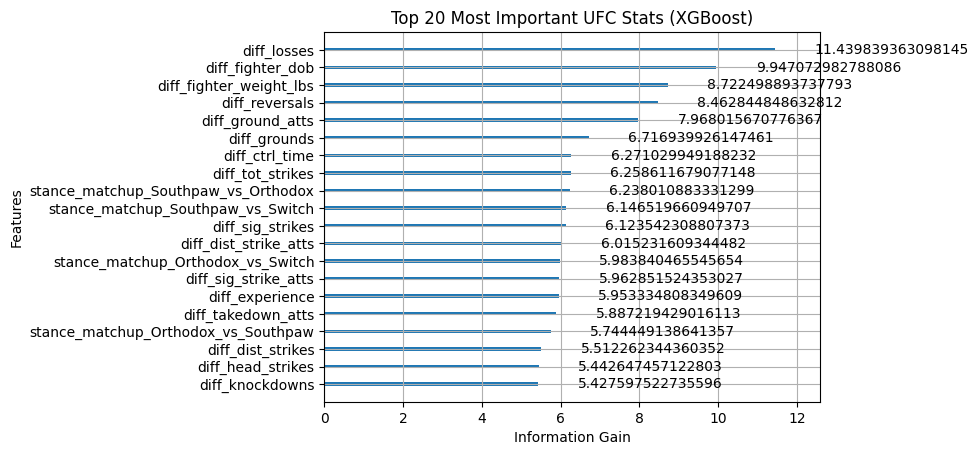

In [12]:
# 1. Predict on the totally unseen Test Set
y_pred = xgb_model.predict(X_test)

# 2. Print Accuracy Metrics
print("="*50)
print(f"FINAL EXAM (TEST) ACCURACY: {accuracy_score(y_test, y_pred):.2%}")
print("="*50)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# 3. Plot Feature Importance (Top 15 Most Important Stats)
plt.figure(figsize=(10, 8))
plot_importance(xgb_model, max_num_features=20, importance_type='gain', 
                title='Top 20 Most Important UFC Stats (XGBoost)',
                xlabel='Information Gain')
plt.show()